# Train-delay prediction

Compare LSTM, Transformer and GNN models with a previous-departure-delay baseline
on later service dates. This notebook opens the recorded results by default.
Set `RETRAIN = True` after downloading the data to run a new experiment; a full
CPU run took about 2.6 hours on the original laptop.

The implementation is split into [data preparation](../train_delay/data.py),
[models](../train_delay/models.py) and [training/evaluation](../train_delay/training.py).
See the [README](../README.md) for setup, assumptions and limitations.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), Path.cwd().parent) if (path / "train_delay").is_dir())
sys.path.insert(0, str(ROOT))
RETRAIN = False  # Use the included results unless you choose to train again.
result_dir = ROOT / "results"
if RETRAIN:
    from train_delay.data import DelayData
    from train_delay.training import run_experiment

    data = DelayData(ROOT / "data")
    result_dir = ROOT / "runs/latest"
    run_experiment(data, result_dir)

## Chronological split

The target is `previous departure delay + delay change`, in minutes. Cleaning
removes duplicates, invalid labels and imputed previous delays. Numerical and
categorical preprocessing learns only from training dates. One unused date
separates adjacent splits, and each history hides its current target delay.

In [2]:
split_summary = pd.read_csv(result_dir / "split_summary.csv")
display(split_summary)

,Split,Start,End,Journeys,Stops
0,train,2026-03-01,2026-04-26,22760,377960
1,val,2026-04-28,2026-05-07,4556,75548
2,test,2026-05-09,2026-05-19,5126,85097


## Model comparison

LSTM reads the ordered history; Transformer attends across it; GNN passes
information along directed route edges within each journey. All three predict a
correction to the previous delay and use the same held-out stops.

Lower MAE, RMSE and P90 absolute error are better. Mean bias is prediction minus
actual delay; negative values mean underprediction. R² is included as a further
measure of fit.

In [3]:
results = pd.read_csv(result_dir / "comparison.csv")
display(results.set_index("Model").round(4))
baseline_mae = results.loc[results.Model.eq("Baseline"), "MAE"].iloc[0]
best = results.loc[results.MAE.idxmin()]
print(f"Lowest MAE: {best.Model}; {(baseline_mae - best.MAE) / baseline_mae:.2%} below baseline.")

,MAE,RMSE,R2,P90_AE,Mean_bias
Model,,,,,
LSTM,0.8334,2.6009,0.9656,2.0016,-0.3817
Transformer,0.8531,2.6280,0.9649,2.0002,-0.2670
GNN,0.8391,2.6125,0.9653,2.0000,-0.3191
Baseline,0.8529,2.6280,0.9649,2.0000,-0.2672


Lowest MAE: LSTM; 2.30% below baseline.


## Error plots

MAE and RMSE use separate, focused axes. Read the numeric labels alongside the
visual differences.

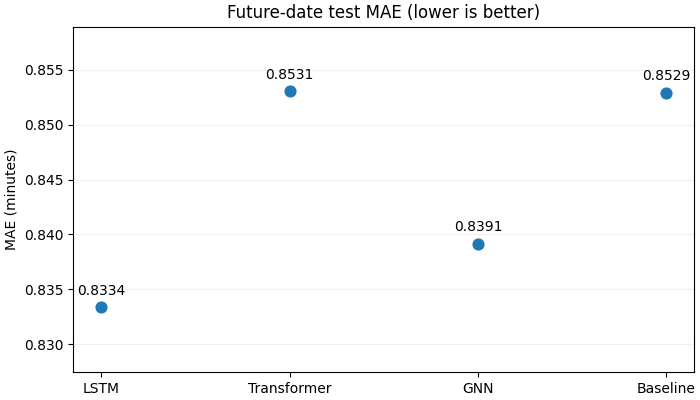

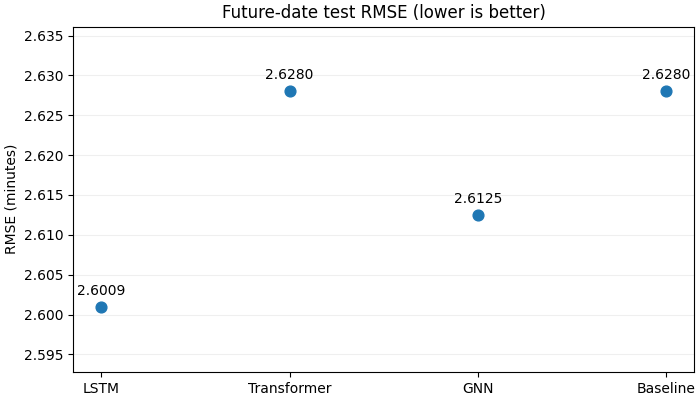

In [4]:
for name in ("mae.png", "rmse.png"):
    display(Image(filename=str(result_dir / name)))

## Validation history

Validation MAE selects the checkpoint, reduces the learning rate and controls
early stopping. The test period is evaluated after training.

,Epochs,Best_validation_MAE
Model,,
LSTM,14,0.916362
Transformer,10,0.939076
GNN,16,0.926962


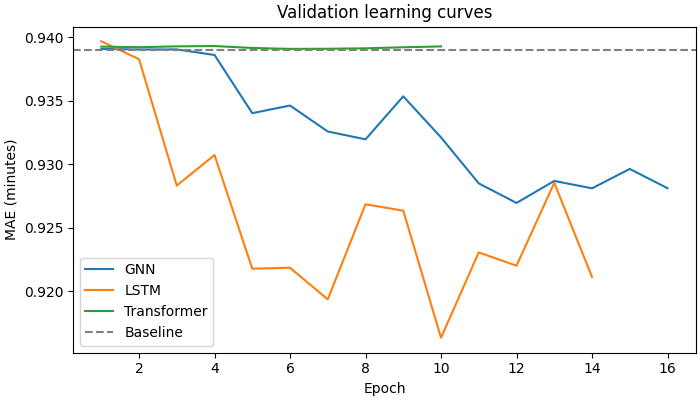

In [5]:
history = pd.read_csv(result_dir / "history.csv")
display(history.groupby("Model", sort=False).agg(Epochs=("Epoch", "max"), Best_validation_MAE=("Validation_MAE", "min")))
display(Image(filename=str(result_dir / "validation_curves.png")))

## Interpretation

In the recorded full-data run, LSTM improves test MAE by about 2.3%, or 1.18
seconds per stop in average absolute error. Its negative mean bias is worse,
and P90 error stays around two minutes across models. The Transformer is
effectively level with the baseline.

This comparison covers one operator, one seed and March–May 2026. More seeds and
chronological test periods are needed before claiming a reliable general
advantage. The GNN describes journey history rather than interactions between
simultaneous trains. See the README for further experiments.